In [38]:
#Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Loading CSV file
df = pd.read_csv("/data/cleaned_data.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [41]:
# Check that the columns required in this notebook are present.
required_columns = [
    "Customer ID",
    "Subscription Length (Months)",
    "Customer Satisfaction Score (1-10)",
    "Daily Watch Time (Hours)",
    "Engagement Rate (1-10)",
    "Payment History (On-Time/Delayed)",
    "Support Queries Logged",
    "Churn Status (Yes/No)"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing from the dataset: {missing_columns}")

if df.empty:
    raise ValueError("The loaded dataset is empty.")

In [42]:
#Checking the first 5 records to confirm the data has loaded successfully
df.head()

,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,Churn Status (Yes/No),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
0,CUST109419,62.0,8.0,1.45,2.0,Smartphone,comedy,north-america,delayed,standard,NO,1.0,41.0,22495.0,0.0,2.0
1,CUST108768,54.0,7.0,5.10,7.0,Laptop,thriller,north-america,on-time,basic,NO,0.0,30.0,70506.0,2.0,1.0
2,CUST107656,25.0,6.0,3.78,6.0,Tablet,sci-fi,north-america,on-time,standard,NO,1.0,24.0,67448.0,2.0,4.0
3,CUST100416,31.0,8.0,2.28,3.0,Tablet,drama,latin-america,on-time,basic,NO,1.0,48.0,65227.5,0.0,3.0
4,CUST103710,19.0,5.0,2.84,5.0,Smartphone,drama,asia-pacific,on-time,basic,NO,2.0,41.0,31250.0,0.0,1.0


In [43]:
#Checking the dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 9901
Number of Columns: 16
Dataset Shape: (9901, 16)


In [44]:
#Checking column names
df.columns.tolist()

['Customer ID',
 'Subscription Length (Months)',
 'Customer Satisfaction Score (1-10)',
 'Daily Watch Time (Hours)',
 'Engagement Rate (1-10)',
 'Device Used Most Often',
 'Genre Preference',
 'Region',
 'Payment History (On-Time/Delayed)',
 'Subscription Plan',
 'Churn Status (Yes/No)',
 'Support Queries Logged',
 'Age',
 'Monthly Income ($)',
 'Promotional Offers Used',
 'Number of Profiles Created']

In [45]:
#Checking datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9901 entries, 0 to 9900
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Customer ID                         9901 non-null   object 
 1   Subscription Length (Months)        9901 non-null   float64
 2   Customer Satisfaction Score (1-10)  9901 non-null   float64
 3   Daily Watch Time (Hours)            9901 non-null   float64
 4   Engagement Rate (1-10)              9901 non-null   float64
 5   Device Used Most Often              9901 non-null   object 
 6   Genre Preference                    9901 non-null   object 
 7   Region                              9901 non-null   object 
 8   Payment History (On-Time/Delayed)   9901 non-null   object 
 9   Subscription Plan                   9901 non-null   object 
 10  Churn Status (Yes/No)               9901 non-null   object 
 11  Support Queries Logged              9901 no

In [46]:
# Converting the target variable to numeric values: Yes = 1, No = 0
# Normalizing text first so extra spaces and letter case do not cause mapping errors.
churn_clean = (
    df["Churn Status (Yes/No)"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df["Churn_Numeric"] = churn_clean.map({
    "yes": 1,
    "no": 0
})

if df["Churn_Numeric"].isna().any():
    invalid_values = df.loc[df["Churn_Numeric"].isna(), "Churn Status (Yes/No)"].unique()
    raise ValueError(f"Missing or unrecognized churn labels found: {invalid_values}")

df["Churn_Numeric"] = df["Churn_Numeric"].astype(int)

print("Churn target converted successfully: Yes = 1, No = 0")
print(df["Churn_Numeric"].value_counts().sort_index())

Churn target converted successfully: Yes = 1, No = 0
Churn_Numeric
0    7432
1    2469
Name: count, dtype: int64


In [47]:
#Checking Percentage
print("Respective Percentage")
df["Churn_Numeric"].value_counts(normalize=True) * 100

Respective Percentage


,proportion
Churn_Numeric,
0,75.063125
1,24.936875


We don't want to create features from:
*   Customer ID
*   Churn Status
*   Churn_Numeric


## 1. Low Watch Time

Customers with very low daily watch time may have lower engagement
with the service and may be more likely to churn.

A value of 1 indicates low watch time, while 0 indicates normal/higher
watch time.

In [48]:
watch_time = pd.to_numeric(df["Daily Watch Time (Hours)"], errors="coerce")

if watch_time.isna().any():
    raise ValueError("Daily Watch Time contains missing or non-numeric values. Recheck the cleaned dataset.")

df["Low_Watch_Time"] = (watch_time < 1).astype(int)

print("Low_Watch_Time feature created.")
print("1 = Less than 1 hour per day; 0 = 1 hour or more.")

Low_Watch_Time feature created.
1 = Less than 1 hour per day; 0 = 1 hour or more.


In [49]:
#Checking Low Watch Time
df[[
    "Daily Watch Time (Hours)",
    "Low_Watch_Time"
]].head(10)

,Daily Watch Time (Hours),Low_Watch_Time
0,1.45,0
1,5.10,0
2,3.78,0
3,2.28,0
4,2.84,0
5,0.90,1
6,3.63,0
7,0.49,1
8,6.03,0
9,1.38,0


In [50]:
#Analysing Low Watch Time in percentage
pd.crosstab(
    df["Low_Watch_Time"],
    df["Churn_Numeric"],
    normalize="index"
) * 100

Churn_Numeric,0,1
Low_Watch_Time,,
0,78.317583,21.682417
1,64.824121,35.175879


## 2. Low Satisfaction

Customers with a satisfaction score of 4 or below are classified
as having low satisfaction.

In [51]:
satisfaction = pd.to_numeric(
    df["Customer Satisfaction Score (1-10)"],
    errors="coerce"
)

if satisfaction.isna().any():
    raise ValueError("Customer Satisfaction contains missing or non-numeric values.")

df["Low_Satisfaction"] = (satisfaction <= 4).astype(int)

print("Low_Satisfaction feature created.")
print("1 = Score 4 or below; 0 = Score above 4.")

Low_Satisfaction feature created.
1 = Score 4 or below; 0 = Score above 4.


In [52]:
#Checking Low Satisfaction
df[[
    "Customer Satisfaction Score (1-10)",
    "Low_Satisfaction"
]].head(10)

,Customer Satisfaction Score (1-10),Low_Satisfaction
0,8.0,0
1,7.0,0
2,6.0,0
3,8.0,0
4,5.0,0
5,4.0,1
6,7.0,0
7,8.0,0
8,5.0,0
9,5.0,0


In [53]:
#Analysing Low Satisfaction
pd.crosstab(
    df["Low_Satisfaction"],
    df["Churn_Numeric"],
    normalize="index"
) * 100

Churn_Numeric,0,1
Low_Satisfaction,,
0,76.776525,23.223475
1,54.687500,45.312500


## 3. Low Engagement

Customers with an engagement rate of 4 or below are classified
as having low engagement.

In [54]:
engagement = pd.to_numeric(df["Engagement Rate (1-10)"], errors="coerce")

if engagement.isna().any():
    raise ValueError("Engagement Rate contains missing or non-numeric values.")

df["Low_Engagement"] = (engagement <= 4).astype(int)

print("Low_Engagement feature created.")
print("1 = Score 4 or below; 0 = Score above 4.")

Low_Engagement feature created.
1 = Score 4 or below; 0 = Score above 4.


In [55]:
#Checking Low Engagement
df[[
    "Engagement Rate (1-10)",
    "Low_Engagement"
]].head(10)

,Engagement Rate (1-10),Low_Engagement
0,2.0,1
1,7.0,0
2,6.0,0
3,3.0,1
4,5.0,0
5,4.0,1
6,4.0,1
7,1.0,1
8,7.0,0
9,6.0,0


In [56]:
#Analysing Low Engagement
pd.crosstab(
    df["Low_Engagement"],
    df["Churn_Numeric"],
    normalize="index"
) * 100

Churn_Numeric,0,1
Low_Engagement,,
0,84.739583,15.260417
1,68.932519,31.067481


## 4. Payment Risk

Customers with delayed payment history are assigned a payment risk
value of 1. Customers with on-time payments receive a value of 0.

In [57]:
# Delayed = 1; On-Time = 0. Unknown values are not automatically treated as safe.
payment_clean = (
    df["Payment History (On-Time/Delayed)"]
    .astype("string")
    .str.strip()
    .str.lower()
)

payment_mapping = {
    "delayed": 1,
    "on-time": 0,
    "on time": 0
}

df["Payment_Risk"] = payment_clean.map(payment_mapping)

if df["Payment_Risk"].isna().any():
    invalid_values = df.loc[
        df["Payment_Risk"].isna(),
        "Payment History (On-Time/Delayed)"
    ].unique()
    raise ValueError(
        "Missing or unrecognized payment-history values found. "
        f"Check the cleaned dataset: {invalid_values}"
    )

df["Payment_Risk"] = df["Payment_Risk"].astype(int)

print("Payment_Risk feature created.")
print("1 = Delayed payment; 0 = On-time payment.")

Payment_Risk feature created.
1 = Delayed payment; 0 = On-time payment.


In [58]:
#Checking Payment Risk
df[[
    "Payment History (On-Time/Delayed)",
    "Payment_Risk"
]].head(10)

,Payment History (On-Time/Delayed),Payment_Risk
0,delayed,1
1,on-time,0
2,on-time,0
3,on-time,0
4,on-time,0
5,on-time,0
6,delayed,1
7,on-time,0
8,on-time,0
9,delayed,1


In [59]:
#Analysing Payment Risk
pd.crosstab(
    df["Payment_Risk"],
    df["Churn_Numeric"],
    normalize="index"
) * 100

Churn_Numeric,0,1
Payment_Risk,,
0,77.408595,22.591405
1,66.381766,33.618234


## 5. High Support Usage

Customers with three or more support queries are classified as
having high support usage.

In [60]:
# 3 or more logged support queries is classified as high usage.
support_queries = pd.to_numeric(df["Support Queries Logged"], errors="coerce")

if support_queries.isna().any():
    raise ValueError("Support Queries Logged contains missing or non-numeric values.")

df["High_Support_Usage"] = (support_queries >= 3).astype(int)

print("High_Support_Usage feature created.")
print("1 = 3 or more support queries; 0 = Fewer than 3.")

High_Support_Usage feature created.
1 = 3 or more support queries; 0 = Fewer than 3.


In [61]:
#Checking High Support Usage
df[[
    "Support Queries Logged",
    "High_Support_Usage"
]].head(10)

,Support Queries Logged,High_Support_Usage
0,1.0,0
1,0.0,0
2,1.0,0
3,1.0,0
4,2.0,0
5,2.0,0
6,2.0,0
7,1.0,0
8,1.0,0
9,2.0,0


In [62]:
#Analysing High Support Usage
pd.crosstab(
    df["High_Support_Usage"],
    df["Churn_Numeric"],
    normalize="index"
) * 100

Churn_Numeric,0,1
High_Support_Usage,,
0,76.498325,23.501675
1,68.783931,31.216069


In [63]:
#Checking all Columns added
new_features = [
    "Low_Watch_Time",
    "Low_Satisfaction",
    "Low_Engagement",
    "Payment_Risk",
    "High_Support_Usage"
]

display(df[new_features].head(10))

,Low_Watch_Time,Low_Satisfaction,Low_Engagement,Payment_Risk,High_Support_Usage
0,0,0,1,1,0
1,0,0,0,0,0
2,0,0,0,0,0
3,0,0,1,0,0
4,0,0,0,0,0
5,1,1,1,0,0
6,0,0,1,1,0
7,1,0,1,0,0
8,0,0,0,0,0
9,0,0,0,1,0


In [64]:
#Checking their distribution
for feature in new_features:
    print(df[feature].value_counts())

Low_Watch_Time
0    7513
1    2388
Name: count, dtype: int64
Low_Satisfaction
0    9133
1     768
Name: count, dtype: int64
Low_Engagement
1    6061
0    3840
Name: count, dtype: int64
Payment_Risk
0    7795
1    2106
Name: count, dtype: int64
High_Support_Usage
0    8059
1    1842
Name: count, dtype: int64


## #Comparing these Features with Churn

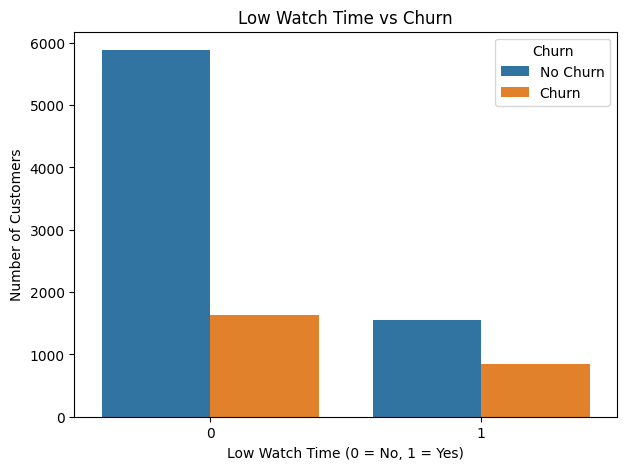

In [65]:
#Low Watch Time vs Churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Low_Watch_Time",
    hue="Churn_Numeric"
)

plt.title("Low Watch Time vs Churn")
plt.xlabel("Low Watch Time (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["No Churn", "Churn"])

plt.show()

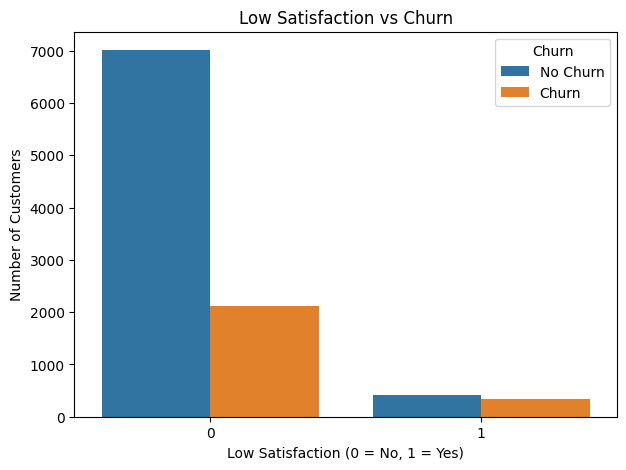

In [66]:
#Low Satisfaction vs Churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Low_Satisfaction",
    hue="Churn_Numeric"
)

plt.title("Low Satisfaction vs Churn")
plt.xlabel("Low Satisfaction (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["No Churn", "Churn"])

plt.show()

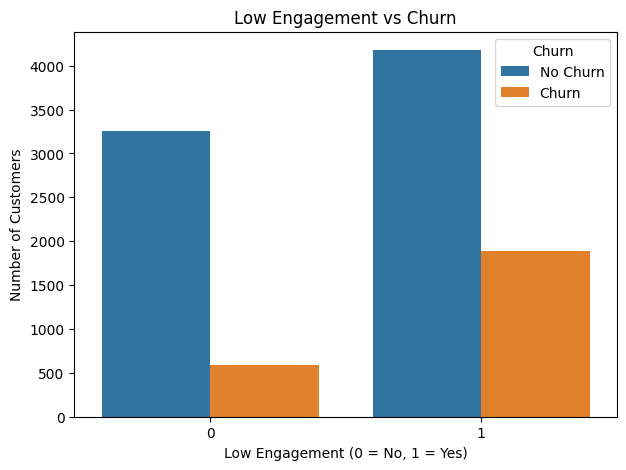

In [67]:
#Low Engagement vs Churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Low_Engagement",
    hue="Churn_Numeric"
)

plt.title("Low Engagement vs Churn")
plt.xlabel("Low Engagement (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["No Churn", "Churn"])

plt.show()

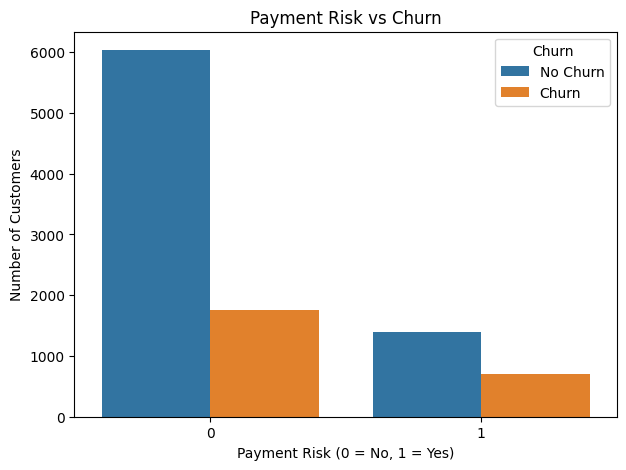

In [68]:
#Payment Risk vs Churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Payment_Risk",
    hue="Churn_Numeric"
)

plt.title("Payment Risk vs Churn")
plt.xlabel("Payment Risk (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["No Churn", "Churn"])

plt.show()

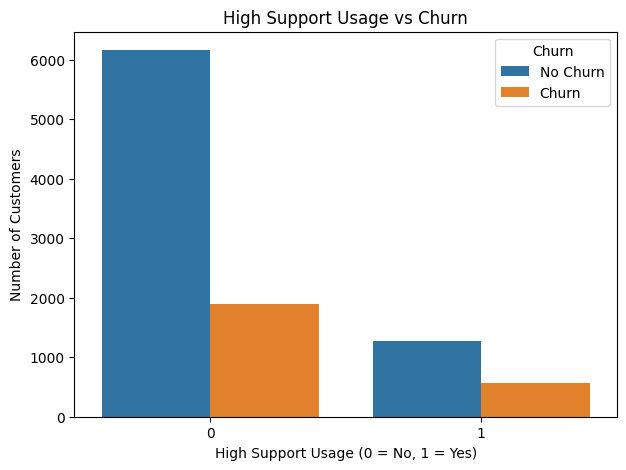

In [69]:
#High Support Usage vs Churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="High_Support_Usage",
    hue="Churn_Numeric"
)

plt.title("High Support Usage vs Churn")
plt.xlabel("High Support Usage (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["No Churn", "Churn"])

plt.show()

In [70]:
# All five engineered features for model comparison

new_features = [
    "Low_Watch_Time",
    "Low_Satisfaction",
    "Low_Engagement",
    "Payment_Risk",
    "High_Support_Usage"
]

print("Engineered features:")
display(df[new_features].head())

print("\nEngineered feature distributions:")
for feature in new_features:
    print(f"\n{feature}")
    print(df[feature].value_counts(dropna=False).sort_index())

Engineered features:


,Low_Watch_Time,Low_Satisfaction,Low_Engagement,Payment_Risk,High_Support_Usage
0,0,0,1,1,0
1,0,0,0,0,0
2,0,0,0,0,0
3,0,0,1,0,0
4,0,0,0,0,0



Engineered feature distributions:

Low_Watch_Time
Low_Watch_Time
0    7513
1    2388
Name: count, dtype: int64

Low_Satisfaction
Low_Satisfaction
0    9133
1     768
Name: count, dtype: int64

Low_Engagement
Low_Engagement
0    3840
1    6061
Name: count, dtype: int64

Payment_Risk
Payment_Risk
0    7795
1    2106
Name: count, dtype: int64

High_Support_Usage
High_Support_Usage
0    8059
1    1842
Name: count, dtype: int64


In [71]:
#Checking all features
df.columns.tolist()

['Customer ID',
 'Subscription Length (Months)',
 'Customer Satisfaction Score (1-10)',
 'Daily Watch Time (Hours)',
 'Engagement Rate (1-10)',
 'Device Used Most Often',
 'Genre Preference',
 'Region',
 'Payment History (On-Time/Delayed)',
 'Subscription Plan',
 'Churn Status (Yes/No)',
 'Support Queries Logged',
 'Age',
 'Monthly Income ($)',
 'Promotional Offers Used',
 'Number of Profiles Created',
 'Churn_Numeric',
 'Low_Watch_Time',
 'Low_Satisfaction',
 'Low_Engagement',
 'Payment_Risk',
 'High_Support_Usage']

In [72]:
#Checking for Duplicate Features
print("Duplicate full rows:", df.duplicated().sum())

if "Customer ID" in df.columns:
    print("Duplicate Customer IDs:", df["Customer ID"].duplicated().sum())

Duplicate full rows: 0
Duplicate Customer IDs: 0


In [73]:
#Checking for missing Values
missing_summary = df.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0])

if df.isna().any().any():
    print("Warning: Missing values remain. Resolve them before model training.")
else:
    print("No missing values found in the feature-engineered dataset.")

,0


No missing values found in the feature-engineered dataset.


## Important
We have created new features,checked the important for prediction till now,and adding columns along with the original columns.

Now saving them in separate csv for clarification

In [ ]:
output_file = "/data/features_engineered_data.csv"
df.to_csv(output_file, index=False)
print("Features dataset exported successfully!")
print("File name:", output_file)
print("Final shape:", df.shape)

Features dataset exported successfully!
File name: /content/drive/Shareddrives/ai/features_engineered_data.csv
Final shape: (9901, 22)
